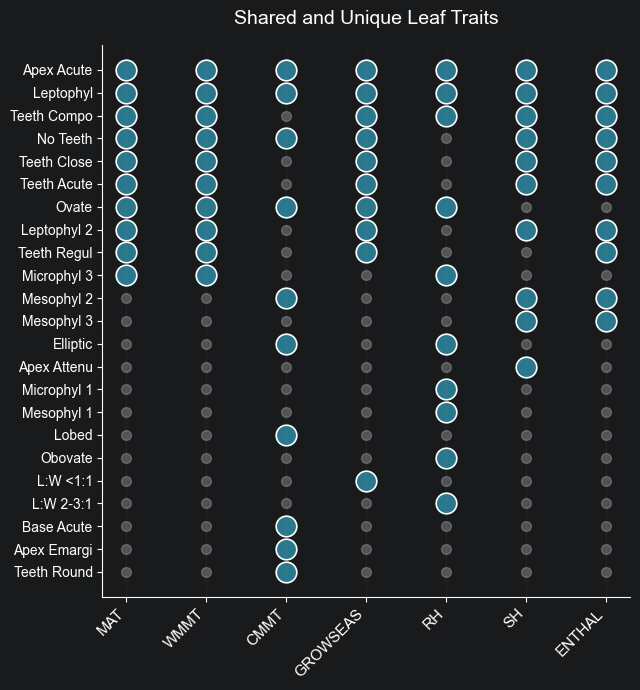

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'

top_features = {
    "MAT": [
        "No Teeth","Microphyl 3","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","Leptophyl 2","Apex Acute"
    ],

    "WMMT": [
        "No Teeth","Microphyl 3","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","Leptophyl 2","Apex Acute"
    ],

    "CMMT": [
        "No Teeth","Apex Emargi","Mesophyl 2","Lobed",
        "Base Acute","Elliptic","Apex Acute",
        "Ovate","Leptophyl","Teeth Round"
    ],

    "GROWSEAS":[
        "No Teeth","Leptophyl 2","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","L:W <1:1","Apex Acute"
    ],

    "RH":[
        "Elliptic","Microphyl 1","Microphyl 3","Teeth Compo",
        "Ovate","Leptophyl","Obovate",
        "L:W 2-3:1","Mesophyl 1","Apex Acute"
    ],

    "SH":[
        "No Teeth","Mesophyl 3","Teeth Close","Teeth Compo",
        "Teeth Acute","Leptophyl 2","Apex Attenu",
        "Leptophyl","Mesophyl 2","Apex Acute"
    ],

    "ENTHAL":[
        "No Teeth","Mesophyl 3","Teeth Close","Teeth Compo",
        "Teeth Acute","Leptophyl 2","Teeth Regul",
        "Leptophyl","Mesophyl 2","Apex Acute"
    ]
}

# ---------------------------------------------------
# 构造 Presence/Absence matrix
# ---------------------------------------------------
all_features = sorted(
    list(set(sum(top_features.values(), [])))
)

df = pd.DataFrame(
    0,
    index=all_features,
    columns=top_features.keys()
)

for var, feats in top_features.items():
    df.loc[feats, var] = 1

# 按出现次数排序
freq = df.sum(axis=1)
df = df.loc[freq.sort_values(ascending=False).index]

# ---------------------------------------------------
# Plot
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5,7))

x_positions = np.arange(len(df.columns))
y_positions = np.arange(len(df.index))

for i, feature in enumerate(df.index):

    for j, variable in enumerate(df.columns):

        if df.iloc[i,j]==1:

            ax.scatter(
                j,
                i,
                s=220,
                color='#2A788E',
                edgecolor='white',
                linewidth=1.2
            )

        else:

            ax.scatter(
                j,
                i,
                s=50,
                color='lightgray',
                alpha=0.3
            )

# ---------------------------------------------------
# labels
# ---------------------------------------------------
ax.set_xticks(x_positions)
ax.set_xticklabels(
    df.columns,
    fontsize=11,
    rotation=45,
    ha='right'
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    df.index,
    fontsize=10
)

ax.invert_yaxis()

# 去掉边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 网格
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.15
)

ax.set_title(
    "Shared and Unique Leaf Traits",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.savefig(
    "Shared_leaf_traits_matrix.svg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

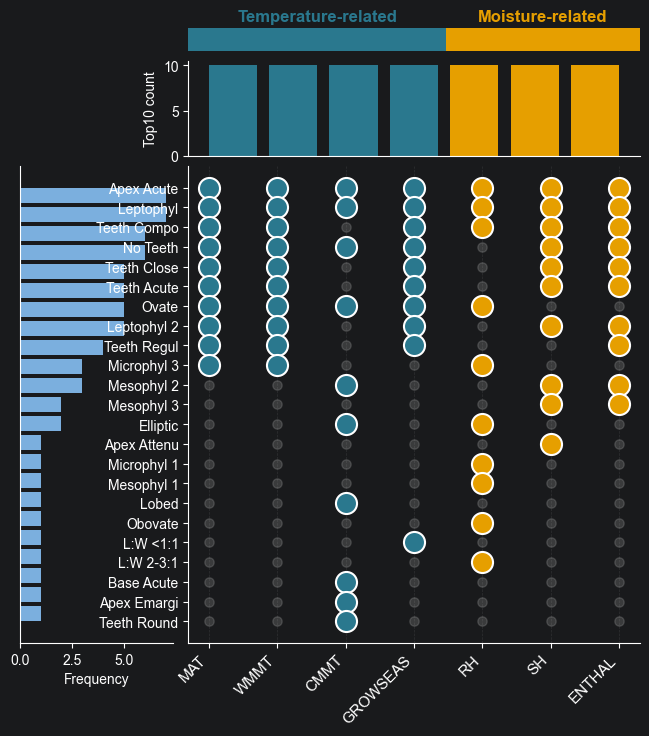

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

plt.rcParams['font.family'] = 'Arial'

# ======================================================
# top10 SHAP features
# ======================================================
top_features = {
    "MAT": [
        "No Teeth","Microphyl 3","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","Leptophyl 2","Apex Acute"
    ],

    "WMMT": [
        "No Teeth","Microphyl 3","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","Leptophyl 2","Apex Acute"
    ],

    "CMMT": [
        "No Teeth","Apex Emargi","Mesophyl 2","Lobed",
        "Base Acute","Elliptic","Apex Acute",
        "Ovate","Leptophyl","Teeth Round"
    ],

    "GROWSEAS":[
        "No Teeth","Leptophyl 2","Teeth Regul","Teeth Compo",
        "Teeth Acute","Leptophyl","Ovate",
        "Teeth Close","L:W <1:1","Apex Acute"
    ],

    "RH":[
        "Elliptic","Microphyl 1","Microphyl 3","Teeth Compo",
        "Ovate","Leptophyl","Obovate",
        "L:W 2-3:1","Mesophyl 1","Apex Acute"
    ],

    "SH":[
        "No Teeth","Mesophyl 3","Teeth Close","Teeth Compo",
        "Teeth Acute","Leptophyl 2","Apex Attenu",
        "Leptophyl","Mesophyl 2","Apex Acute"
    ],

    "ENTHAL":[
        "No Teeth","Mesophyl 3","Teeth Close","Teeth Compo",
        "Teeth Acute","Leptophyl 2","Teeth Regul",
        "Leptophyl","Mesophyl 2","Apex Acute"
    ]
}

# ======================================================
# matrix
# ======================================================
all_features = sorted(list(set(sum(top_features.values(), []))))

df = pd.DataFrame(
    0,
    index=all_features,
    columns=top_features.keys()
)

for var, feats in top_features.items():
    df.loc[feats, var] = 1

freq = df.sum(axis=1)

df["freq"] = freq
df = df.sort_values("freq", ascending=False)

freq = df["freq"]
df = df.drop(columns="freq")

# ======================================================
# figure
# ======================================================
fig = plt.figure(figsize=(8,8))

gs = GridSpec(
    3,
    2,
    width_ratios=[1.7,5],
    height_ratios=[0.25,1,5],
    hspace=0.05,
    wspace=0.05
)

ax_ann = fig.add_subplot(gs[0,1])
ax_top = fig.add_subplot(gs[1,1])
ax_left = fig.add_subplot(gs[2,0])
ax = fig.add_subplot(gs[2,1])

# ======================================================
# annotation bar
# ======================================================
temp_color = '#2A788E'
moist_color = '#E69F00'

colors = [
    temp_color,temp_color,temp_color,temp_color,
    moist_color,moist_color,moist_color
]

for i,c in enumerate(colors):
    ax_ann.bar(
        i,
        1,
        color=c,
        width=1
    )

ax_ann.set_xlim(-0.5,6.5)

ax_ann.set_xticks([])
ax_ann.set_yticks([])

for spine in ax_ann.spines.values():
    spine.set_visible(False)

ax_ann.text(
    1.5,
    1.3,
    "Temperature-related",
    ha='center',
    fontsize=12,
    color=temp_color,
    weight='bold'
)

ax_ann.text(
    5,
    1.3,
    "Moisture-related",
    ha='center',
    fontsize=12,
    color=moist_color,
    weight='bold'
)

# ======================================================
# top bar
# ======================================================
col_count = df.sum(axis=0)

bar_colors = colors

ax_top.bar(
    np.arange(len(col_count)),
    col_count,
    color=bar_colors
)

ax_top.set_ylabel("Top10 count")

ax_top.set_xticks([])

ax_top.spines['top'].set_visible(False)
ax_top.spines['right'].set_visible(False)

# ======================================================
# left bar
# ======================================================
y = np.arange(len(df))

ax_left.barh(
    y,
    freq,
    color='#7BAFDE'
)

ax_left.invert_yaxis()

ax_left.set_xlabel("Frequency")

ax_left.set_yticks([])

ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# ======================================================
# matrix
# ======================================================
for i, feature in enumerate(df.index):

    for j, variable in enumerate(df.columns):

        if df.iloc[i,j] == 1:

            if j <= 3:
                color = temp_color
            else:
                color = moist_color

            ax.scatter(
                j,
                i,
                s=230,
                color=color,
                edgecolor='white',
                linewidth=1.5,
                zorder=3
            )

        else:

            ax.scatter(
                j,
                i,
                s=45,
                color='lightgray',
                alpha=0.18
            )

ax.set_xticks(np.arange(len(df.columns)))

ax.set_xticklabels(
    df.columns,
    fontsize=11,
    rotation=45,
    ha='right'
)

ax.set_yticks(np.arange(len(df.index)))

ax.set_yticklabels(
    df.index,
    fontsize=10
)

ax.invert_yaxis()

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.15
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ======================================================
plt.savefig(
    "Figure8H_Final_Nature_style.svg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()